# Día 5 — PCA, selección de variables e ingeniería de características

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Hasta ahora usamos las variables tal como venían. Hoy trabajamos **sobre las variables mismas**, con tres herramientas distintas que responden tres preguntas distintas:

| Herramienta | Pregunta | ¿Mira la respuesta `y`? | Qué entrega |
|---|---|---|---|
| **PCA** (reducción de dimensionalidad) | ¿Puedo resumir muchas variables en pocas, perdiendo poca información? | No | Variables **nuevas** (componentes), combinaciones de las originales |
| **Selección de variables** | ¿Cuáles de mis variables ayudan de verdad a predecir? | Sí | Un **subconjunto** de las variables originales |
| **Ingeniería de características** | ¿Puedo crear variables que expresen mejor lo que sé del problema? | No necesariamente | Variables **nuevas** creadas por nosotros (cocientes, logaritmos, indicadores) |

## Cómo está organizada cada parte

| Paso | Qué hacemos |
|---|---|
| 1. Mirar los datos | `head`, tipos y resumen |
| 2. Entender y graficar | ¿Qué variables repiten información? ¿Cuáles se relacionan con la respuesta? |
| 3. Limpiar y preparar | Faltantes, logaritmo, codificación y escalado, **con el antes y el después** |
| 4. Línea base | Lo que obtenemos **sin** la herramienta |
| 5. La técnica a mano | Con números pequeños |
| 6. Versión simple con scikit-learn | Pocas líneas comentadas |
| 7. Métricas a mano y con scikit-learn | Siempre **Train frente a Validation** |
| 8. Hiperparámetros, uno por uno | Qué controla cada uno |
| 9. Probar combinaciones con `for` | Contra la línea base |
| 10. Resultado final | Qué elegimos y por qué |

## Los datasets (los mismos de días anteriores)

| Parte | Dataset | Tipo de problema | Herramienta |
|---|---|---|---|
| A | CC GENERAL (8 949 clientes de tarjeta, Día 4) | Clustering | PCA |
| B | BankChurners (10 127 clientes, Días 2 y 3) | Clasificación: ¿abandona? | Selección de variables |
| C | BankChurners y CC GENERAL | Clasificación y clustering | Ingeniería de características |
| D | Los tres anteriores + Credit Risk (Día 3) | Todos | **Comparación final**: ¿qué preparación funciona mejor en cada dataset? |

# 0. Librerías y funciones comunes

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"      # evita avisos de K-Means en Windows; no cambia resultados
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np                           # cálculos numéricos
import pandas as pd                          # tablas
import matplotlib.pyplot as plt              # gráficos

from sklearn.model_selection import train_test_split                     # dividir datos
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures   # escalar, codificar, crear potencias
from sklearn.impute import SimpleImputer                                 # rellenar faltantes
from sklearn.compose import ColumnTransformer                            # preparar columnas distintas
from sklearn.pipeline import Pipeline                                    # encadenar pasos
from sklearn.decomposition import PCA                                    # análisis de componentes principales
from sklearn.cluster import KMeans                                       # clustering
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE, SelectFromModel   # selección
from sklearn.dummy import DummyClassifier                                # línea base
from sklearn.neighbors import KNeighborsClassifier                       # KNN
from sklearn.ensemble import RandomForestClassifier                      # bosque aleatorio
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, silhouette_score

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
for f in ["CC_GENERAL.csv", "BankChurners.csv", "credit_risk_dataset.csv"]:
    print("Encontrado" if (DATA_DIR / f).exists() else "FALTA", "→", (DATA_DIR / f).resolve())

Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\CC_GENERAL.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\BankChurners.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\credit_risk_dataset.csv


In [2]:
def metricas(y_real, y_pred):
    # Las cuatro métricas de la clase positiva (1)
    return {"accuracy": accuracy_score(y_real, y_pred),
            "precision": precision_score(y_real, y_pred, zero_division=0),
            "recall": recall_score(y_real, y_pred, zero_division=0),
            "f1": f1_score(y_real, y_pred, zero_division=0)}

def evaluar(modelo, nombre, X_tr, y_tr, X_va, y_va):
    # El modelo YA está entrenado con Train: medimos F1 en Train y en Validation y la brecha entre ambos
    f1_tr = f1_score(y_tr, modelo.predict(X_tr), zero_division=0)
    f1_va = f1_score(y_va, modelo.predict(X_va), zero_division=0)
    return {"modelo": nombre, "f1_train": f1_tr, "f1_val": f1_va, "brecha": f1_tr - f1_va}

# Parte A · PCA con los clientes de tarjeta (CC GENERAL)

**El problema.** En el Día 4 escogimos 9 de las 17 variables «a ojo» porque muchas repetían lo mismo. ¿Hay una forma **automática** de resumir las 17 en pocas variables nuevas sin perder casi nada de información? Eso hace **PCA** (*Principal Component Analysis*, análisis de componentes principales).

## A.1 Mirar los datos

In [3]:
cc = pd.read_csv(DATA_DIR / "CC_GENERAL.csv")
print("Filas y columnas:", cc.shape)
cc.head()

Filas y columnas: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


Son las mismas 17 variables de comportamiento del Día 4 (más `CUST_ID`). Varias miden casi lo mismo: `PURCHASES` (total comprado) es la suma de `ONEOFF_PURCHASES` (compras de un pago) e `INSTALLMENTS_PURCHASES` (en cuotas); `PURCHASES_FREQUENCY` y `PURCHASES_TRX` (número de compras) cuentan la actividad de compra de dos formas; `CASH_ADVANCE`, `CASH_ADVANCE_FREQUENCY` y `CASH_ADVANCE_TRX` describen los avances en efectivo.

## A.2 Entender y graficar: ¿cuánto se repiten las variables?

La **correlación** va de −1 a 1: cerca de 1, dos variables suben juntas; cerca de 0, no tienen relación lineal. Si muchas parejas tienen correlación alta, hay información repetida: el terreno ideal para PCA.

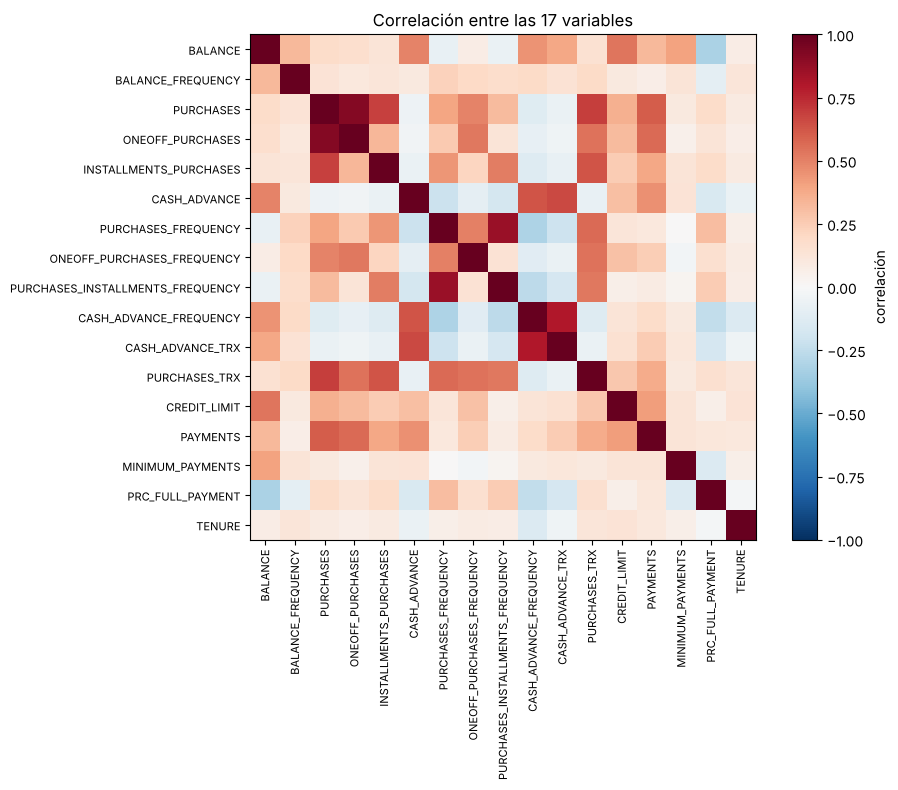

Parejas con |correlación| > 0,6: 9
   PURCHASES                          ONEOFF_PURCHASES                   +0.92
   PURCHASES_FREQUENCY                PURCHASES_INSTALLMENTS_FREQUENCY   +0.86
   CASH_ADVANCE_FREQUENCY             CASH_ADVANCE_TRX                   +0.80
   PURCHASES                          PURCHASES_TRX                      +0.69
   PURCHASES                          INSTALLMENTS_PURCHASES             +0.68
   CASH_ADVANCE                       CASH_ADVANCE_TRX                   +0.66
   CASH_ADVANCE                       CASH_ADVANCE_FREQUENCY             +0.63
   INSTALLMENTS_PURCHASES             PURCHASES_TRX                      +0.63
   PURCHASES                          PAYMENTS                           +0.60


In [4]:
VARS17 = [c for c in cc.columns if c != "CUST_ID"]                  # las 17 variables de comportamiento
corr = cc[VARS17].corr()                                            # matriz de correlaciones 17 × 17
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(17)); ax.set_xticklabels(VARS17, rotation=90, fontsize=8)
ax.set_yticks(range(17)); ax.set_yticklabels(VARS17, fontsize=8)
plt.colorbar(im, label="correlación"); plt.title("Correlación entre las 17 variables"); plt.tight_layout(); plt.show()

pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(VARS17) for b in VARS17[i + 1:] if abs(corr.loc[a, b]) > 0.6]
print(f"Parejas con |correlación| > 0,6: {len(pares)}")
for a, b, r in sorted(pares, key=lambda t: -abs(t[2])):
    print(f"   {a:34s} {b:34s} {r:+.2f}")

**Lee el mapa.** Los cuadros rojos fuera de la diagonal son parejas que suben juntas: 9 parejas superan 0,6 (por ejemplo, compras totales y compras de un pago, 0,92). Hay dos «familias» claras: las variables de **compras** (totales, de un pago, en cuotas, frecuencias y número de compras) y las de **avances en efectivo**. Si dos variables dicen casi lo mismo, una sola dirección podría resumirlas: eso es un **componente principal**.

## A.3 Limpiar y preparar, paso a paso

**Paso 1: faltantes**, igual que en el Día 4.

In [5]:
print("Faltantes:", cc[VARS17].isna().sum()[lambda s: s > 0].to_dict())
cc = cc.dropna(subset=["CREDIT_LIMIT"]).copy()                              # 1 cliente sin límite
cc["MINIMUM_PAYMENTS"] = cc["MINIMUM_PAYMENTS"].fillna(cc["MINIMUM_PAYMENTS"].median())
print("Clientes:", len(cc))

Faltantes: {'CREDIT_LIMIT': 1, 'MINIMUM_PAYMENTS': 313}
Clientes: 8949


**Paso 2: logaritmo de los montos en dólares.** Igual que en el Día 4: los montos son muy asimétricos y unos pocos clientes enormes dominarían. Aplicamos $\log(1+x)$ a las 8 columnas en dólares y dejamos las frecuencias (0 a 1), los conteos y la antigüedad.

In [6]:
MONTOS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
          "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
def preparar_cc(df):
    # log(1 + x) solo a los montos; no aprende nada de los datos
    d = df[VARS17].copy()
    d[MONTOS] = np.log1p(d[MONTOS])
    return d
print("Antes:");   print(cc[VARS17].head(3).round(2))
print("\nDespués del logaritmo:"); print(preparar_cc(cc).head(3).round(2))

Antes:
   BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  ONEOFF_PURCHASES_FREQUENCY  \
0    40.90               0.82      95.40              0.00                    95.4          0.00                 0.17                         0.0   
1  3202.47               0.91       0.00              0.00                     0.0       6442.95                 0.00                         0.0   
2  2495.15               1.00     773.17            773.17                     0.0          0.00                 1.00                         1.0   

   PURCHASES_INSTALLMENTS_FREQUENCY  CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX  PURCHASES_TRX  CREDIT_LIMIT  PAYMENTS  MINIMUM_PAYMENTS  PRC_FULL_PAYMENT  TENURE  
0                              0.08                    0.00                 0              2        1000.0    201.80            139.51              0.00      12  
1                              0.00                    0.25           

**Paso 3: dividir en Train y Validation.** PCA **aprende** (las medias, las desviaciones y las direcciones de los componentes), así que lo ajustamos solo con Train y comprobamos en Validation que el resumen funciona igual de bien con clientes nuevos.

In [7]:
train_cc, val_cc = train_test_split(cc, test_size=0.30, random_state=42)
print("Train:", len(train_cc), "| Validation:", len(val_cc))

Train: 6264 | Validation: 2685


**Paso 4: estandarizar.** PCA busca las direcciones con **más varianza**. Si no escalamos, gana la variable con números más grandes, no la más informativa. Lo vemos con un PCA **sin escalar**:

In [8]:
pca_sin_escalar = PCA(n_components=1).fit(preparar_cc(train_cc))       # PCA directo, sin estandarizar
pesos = pd.Series(pca_sin_escalar.components_[0], index=VARS17).abs().sort_values(ascending=False)
print("Peso de cada variable en el 1.er componente SIN escalar (las 5 mayores):"); print(pesos.head(5).round(2))
print("\nVarianza de esas variables:"); print(preparar_cc(train_cc)[pesos.index[:5]].var().round(1))

Peso de cada variable en el 1.er componente SIN escalar (las 5 mayores):
PURCHASES_TRX             0.99
INSTALLMENTS_PURCHASES    0.07
PURCHASES                 0.06
ONEOFF_PURCHASES          0.06
CASH_ADVANCE              0.03
dtype: float64

Varianza de esas variables:
PURCHASES_TRX             609.9
INSTALLMENTS_PURCHASES      9.5
PURCHASES                   8.5
ONEOFF_PURCHASES           10.5
CASH_ADVANCE               12.7
dtype: float64


Sin escalar, el primer componente es casi solo `PURCHASES_TRX` (peso 0,99), simplemente porque es un **conteo** con varianza ≈ 610, mientras los montos en logaritmo tienen varianzas ≈ 10 y las frecuencias (0 a 1), ≈ 0,1. Por eso **siempre se estandariza antes de PCA**: todas las variables quedan con varianza 1 y compiten en igualdad.

In [9]:
escalador = StandardScaler().fit(preparar_cc(train_cc))     # medias y desviaciones de Train
X_train = escalador.transform(preparar_cc(train_cc))        # 6 264 × 17, ya estandarizado
X_val = escalador.transform(preparar_cc(val_cc))            # 2 685 × 17, con las medias de Train
print("Varianza de cada columna en Train (todas 1):", X_train.var(axis=0).round(2)[:6], "...")
pd.DataFrame(X_train, columns=VARS17).head(3).round(2)

Varianza de cada columna en Train (todas 1): [1. 1. 1. 1. 1. 1.] ...


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,0.75,0.52,-1.67,-0.98,-1.09,1.74,-1.22,-0.68,-0.92,1.41,2.81,-0.59,0.08,1.77,0.30,0.50,0.36
1,-1.53,-2.58,0.31,-0.98,0.79,-0.94,-0.60,-0.68,-0.50,-0.68,-0.47,-0.35,0.73,-1.07,-2.15,-0.24,0.36
2,-1.54,-0.26,0.09,-0.98,0.58,-0.94,0.64,-0.68,0.76,-0.68,-0.47,-0.23,-1.45,-0.86,-0.79,2.90,0.36


## A.4 Línea base: no reducir nada

Sin PCA usamos las **17** columnas. La pregunta de PCA es: **¿con cuántas columnas nuevas podemos quedarnos sin perder casi nada?**

La medida es el **error de reconstrucción**: resumimos al cliente en pocos componentes, intentamos reconstruir sus 17 valores a partir del resumen y medimos cuánto nos equivocamos (error cuadrático medio, en desviaciones). Dos referencias:

- Con **17 componentes** (no reducir), la reconstrucción es perfecta: error **0**.
- Con **0 componentes**, lo mejor que podemos hacer es decir «el cliente promedio» (todo en 0): el error es la varianza de cada columna, **1**.

Un buen resumen debe tener **pocas columnas y error cercano a 0**.

## A.5 PCA a mano

**La idea.** Imagina una nube de puntos alargada como un cigarro. PCA busca la dirección en la que la nube **más se estira** (más varianza): ese es el **primer componente**. Luego busca la dirección perpendicular que más se estira de lo que queda: el segundo. Y así sucesivamente.

Si la nube es muy alargada, basta con decir **en qué punto del cigarro** está cada cliente (una sola coordenada) y casi no perdemos información.

**Ejemplo con 6 clientes y 2 variables ya estandarizadas** ($x_1$ = compras, $x_2$ = número de compras):

In [10]:
mini = np.array([[-2.0, -1.6], [-1.0, -1.2], [-0.5, 0.1], [0.5, 0.3], [1.0, 1.4], [2.0, 1.0]])
print("Paso 0, los datos (ya tienen media 0):", mini.mean(axis=0).round(2))

# Paso 1: matriz de covarianzas = cuánto varía cada variable y cuánto varían juntas
cov = (mini.T @ mini) / (len(mini) - 1)
print("\nPaso 1, matriz de covarianzas:"); print(cov.round(3))

# Paso 2: las direcciones (vectores propios) y cuánta varianza hay en cada una (valores propios)
valores, vectores = np.linalg.eigh(cov)                 # numpy los entrega de menor a mayor
orden = valores.argsort()[::-1]                          # los ordenamos de mayor a menor
valores, vectores = valores[orden], vectores[:, orden]
print("\nPaso 2, varianza en cada dirección:", valores.round(3))
print("Dirección del 1.er componente:", vectores[:, 0].round(3), "| del 2.º:", vectores[:, 1].round(3))

# Paso 3: proporción de varianza explicada
print("\nPaso 3, varianza explicada:", (valores / valores.sum()).round(3))

# Paso 4: la nueva coordenada de cada cliente = proyección sobre la dirección
pc1 = mini @ vectores[:, 0]
print("\nPaso 4, coordenada PC1 de cada cliente:", pc1.round(2))
c = mini[0]; v = vectores[:, 0]
print(f"   Cliente 1 a mano: {c[0]}·{v[0]:.3f} + ({c[1]})·{v[1]:.3f} = {c[0]*v[0] + c[1]*v[1]:.2f}")

# Paso 5: reconstruir con solo PC1 y medir el error
reconstruido = np.outer(pc1, vectores[:, 0])
print("\nPaso 5, error de reconstrucción con 1 componente:", round(((mini - reconstruido) ** 2).mean(), 4))

Paso 0, los datos (ya tienen media 0): [0. 0.]

Paso 1, matriz de covarianzas:
[[2.1   1.58 ]
 [1.58  1.412]]

Paso 2, varianza en cada dirección: [3.373 0.139]
Dirección del 1.er componente: [-0.779 -0.627] | del 2.º: [ 0.627 -0.779]

Paso 3, varianza explicada: [0.96 0.04]

Paso 4, coordenada PC1 de cada cliente: [ 2.56  1.53  0.33 -0.58 -1.66 -2.18]
   Cliente 1 a mano: -2.0·-0.779 + (-1.6)·-0.627 = 2.56

Paso 5, error de reconstrucción con 1 componente: 0.0579


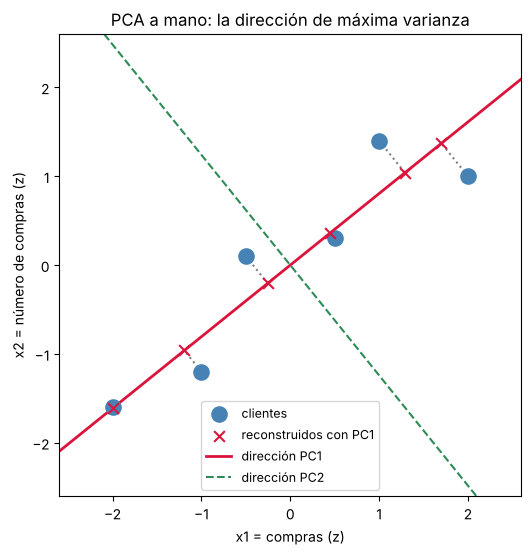

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(mini[:, 0], mini[:, 1], s=120, color="steelblue", zorder=3, label="clientes")
ax.scatter(reconstruido[:, 0], reconstruido[:, 1], s=60, color="crimson", marker="x", zorder=4, label="reconstruidos con PC1")
for p, r in zip(mini, reconstruido): ax.plot([p[0], r[0]], [p[1], r[1]], color="gray", ls=":")   # lo que se pierde
ax.axline((0, 0), slope=vectores[1, 0] / vectores[0, 0], color="crimson", lw=2, label="dirección PC1")
ax.axline((0, 0), slope=vectores[1, 1] / vectores[0, 1], color="seagreen", lw=1.5, ls="--", label="dirección PC2")
ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6); ax.set_aspect("equal")
ax.set_xlabel("x1 = compras (z)"); ax.set_ylabel("x2 = número de compras (z)"); ax.legend(fontsize=9)
ax.set_title("PCA a mano: la dirección de máxima varianza"); plt.show()

**Lee los resultados.**

- La nube se estira en diagonal: la dirección de PC1 es $(0{,}78;\ 0{,}63)$ (numpy la entregó con el signo contrario, que es la misma recta). PC1 **suma las dos variables**, con algo más de peso en compras: PC1 ≈ «nivel de compra».
- PC1 explica el **96 %** de la varianza; PC2, solo el 4 %.
- La **coordenada** de un cliente en PC1 es una suma ponderada de sus variables: para el cliente 1, $(-2)(-0{,}779) + (-1{,}6)(-0{,}627) = 2{,}56$.
- Las **líneas punteadas** del gráfico son lo que se pierde al quedarnos solo con PC1: distancias pequeñas, porque PC2 casi no tiene información.

## A.6 La versión simple con scikit-learn

Los mismos pasos en tres líneas: crear, `fit` (aprende las direcciones) y `transform` (calcula las coordenadas).

In [12]:
pca_mini = PCA(n_components=2)          # 1) crear: queremos 2 componentes
pca_mini.fit(mini)                      # 2) aprender las direcciones
print("Varianza explicada:", pca_mini.explained_variance_ratio_.round(3))
print("Direcciones (components_):"); print(pca_mini.components_.round(3))
print("Coordenadas PC1 (transform):", pca_mini.transform(mini)[:, 0].round(2))

Varianza explicada: [0.96 0.04]
Direcciones (components_):
[[ 0.779  0.627]
 [-0.627  0.779]]
Coordenadas PC1 (transform): [-2.56 -1.53 -0.33  0.58  1.66  2.18]


Coinciden con el cálculo a mano, con el **signo** invertido: $(0{,}78;\ 0{,}63)$ y $(-0{,}78;\ -0{,}63)$ son la misma recta, y las coordenadas cambian de signo (−2,56 en lugar de 2,56). Lo que importa es la recta, no hacia qué lado apunta.

Ahora con los clientes reales: **17 variables → 2 componentes**.

In [13]:
pca2 = PCA(n_components=2, random_state=42)        # 1) crear
pca2.fit(X_train)                                   # 2) aprender con Train
Z_train = pca2.transform(X_train)                   # 3) coordenadas de cada cliente de Train
print("Varianza explicada por PC1 y PC2:", pca2.explained_variance_ratio_.round(3),
      "| total:", round(pca2.explained_variance_ratio_.sum(), 3))
print("\nAsí queda cada cliente: 2 columnas en lugar de 17")
pd.DataFrame(Z_train, columns=["PC1", "PC2"]).head(3).round(2)

Varianza explicada por PC1 y PC2: [0.299 0.219] | total: 0.518

Así queda cada cliente: 2 columnas en lugar de 17


,PC1,PC2
0,-3.60,2.05
1,0.20,-3.41
2,1.41,-2.91


**¿Qué significa cada componente?** Se lee en las **cargas** (*loadings*, `components_`): el peso de cada variable original en el componente. Cargas grandes (positivas o negativas) son las variables que «arman» el componente.

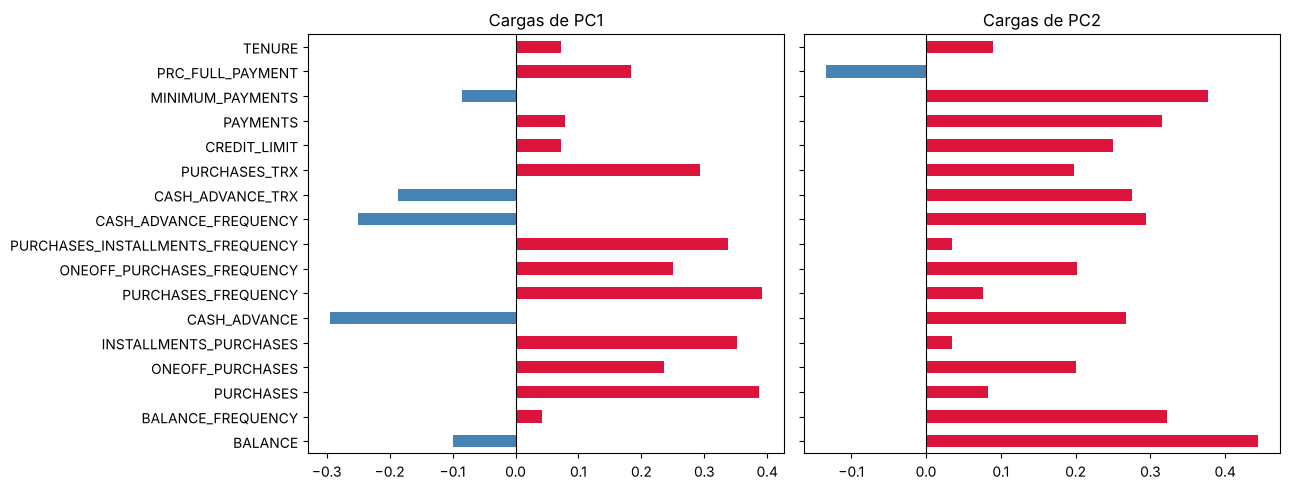

                                   PC1   PC2
PURCHASES                         0.39  0.08
PURCHASES_FREQUENCY               0.39  0.08
INSTALLMENTS_PURCHASES            0.35  0.03
PURCHASES_INSTALLMENTS_FREQUENCY  0.34  0.03
PURCHASES_TRX                     0.29  0.20
ONEOFF_PURCHASES_FREQUENCY        0.25  0.20
ONEOFF_PURCHASES                  0.24  0.20
PRC_FULL_PAYMENT                  0.18 -0.13
PAYMENTS                          0.08  0.32
TENURE                            0.07  0.09
CREDIT_LIMIT                      0.07  0.25
BALANCE_FREQUENCY                 0.04  0.32
MINIMUM_PAYMENTS                 -0.09  0.38
BALANCE                          -0.10  0.44
CASH_ADVANCE_TRX                 -0.19  0.28
CASH_ADVANCE_FREQUENCY           -0.25  0.29
CASH_ADVANCE                     -0.30  0.27


In [14]:
cargas = pd.DataFrame(pca2.components_.T, index=VARS17, columns=["PC1", "PC2"])
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for i, pc in enumerate(["PC1", "PC2"]):
    cargas[pc].plot(kind="barh", ax=ax[i], color=["crimson" if v > 0 else "steelblue" for v in cargas[pc]])
    ax[i].set_title(f"Cargas de {pc}"); ax[i].axvline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()
print(cargas.round(2).sort_values("PC1", ascending=False))

**Interpretación.**

- **PC1 = «compra con la tarjeta».** Cargas positivas grandes en compras totales, frecuencia de compra, compras en cuotas y número de compras; negativas en avances en efectivo. Un cliente con PC1 alto compra mucho y seguido; con PC1 bajo, casi no compra (y tiende a usar avances).
- **PC2 = «deuda y uso de efectivo».** Cargas grandes en saldo, pagos mínimos, pagos, avances y límite. Un PC2 alto es un cliente con saldo alto que mueve mucho dinero.

¡Son casi los dos ejes que distinguían los segmentos del Día 4! PCA los encontró **sin que nadie le dijera nada**.

## A.7 Métricas a mano y con scikit-learn: Train frente a Validation

Dos métricas:

1. **Varianza explicada** = varianza de cada componente / varianza total. A mano: los valores propios de la matriz de covarianzas de Train.
2. **Error de reconstrucción** = promedio de $(x - \hat{x})^2$, donde $\hat{x}$ se reconstruye con `inverse_transform`. Lo medimos en **Train y en Validation**: si en Validation fuera mucho mayor, las direcciones solo servirían para los clientes de Train.

In [15]:
# 1) Varianza explicada a mano: valores propios de la matriz de covarianzas de Train
cov_train = np.cov(X_train, rowvar=False)                  # 17 × 17
valores_train = np.sort(np.linalg.eigvalsh(cov_train))[::-1]
print("A mano       — varianza explicada PC1, PC2:", (valores_train[:2] / valores_train.sum()).round(3))
print("scikit-learn — explained_variance_ratio_: ", pca2.explained_variance_ratio_.round(3))

# 2) Error de reconstrucción a mano, para el primer cliente
x = X_train[0]
z = pca2.components_ @ x                                   # sus 2 coordenadas (los datos ya tienen media 0)
x_rec = pca2.components_.T @ z                             # volver a 17 columnas
print(f"\nCliente 1: coordenadas {z.round(2)}, error de reconstrucción {((x - x_rec) ** 2).mean():.3f}")

def error_rec(modelo, X):
    # promedio de (x − x reconstruido)², con scikit-learn
    return ((X - modelo.inverse_transform(modelo.transform(X))) ** 2).mean()
print(f"\nError de reconstrucción con 2 componentes → Train: {error_rec(pca2, X_train):.3f} | Validation: {error_rec(pca2, X_val):.3f}")

A mano       — varianza explicada PC1, PC2: [0.299 0.219]
scikit-learn — explained_variance_ratio_:  [0.299 0.219]

Cliente 1: coordenadas [-3.6   2.05], error de reconstrucción 0.485

Error de reconstrucción con 2 componentes → Train: 0.482 | Validation: 0.490


**Lee la salida.** Con 2 componentes se explica cerca del 52 % de la varianza y el error de reconstrucción es ≈ 0,48 (la línea base sin componentes era 1): reducimos el error a la mitad usando 2 columnas en lugar de 17. En Validation el error es **casi igual** que en Train: las direcciones aprendidas sirven para clientes nuevos.

## A.8 Los hiperparámetros de PCA, uno por uno

| Hiperparámetro | Qué controla | Por defecto |
|---|---|---|
| `n_components` | Cuántos componentes guardar. Un **entero** (2) fija el número; un **decimal** (0.9) pide «los necesarios para explicar el 90 % de la varianza»; `None` guarda todos | `None` |
| `whiten` | Si es `True`, reescala cada componente para que tenga varianza 1. Útil antes de algunos modelos; cambia las distancias | `False` |
| `svd_solver` | El método numérico para calcular las direcciones (`"auto"`, `"full"`, `"randomized"`). `"randomized"` es más rápido con datos enormes y da un resultado aproximado | `"auto"` |
| `random_state` | Semilla, solo importa con el método aleatorio | `None` |

In [16]:
pca90 = PCA(n_components=0.90).fit(X_train)                 # «los componentes necesarios para el 90 %»
print("n_components=0.90 →", pca90.n_components_, "componentes, varianza", round(pca90.explained_variance_ratio_.sum(), 3))

sin_w = PCA(n_components=3).fit(X_train).transform(X_train)
con_w = PCA(n_components=3, whiten=True).fit(X_train).transform(X_train)
print("\nVarianza de cada componente — whiten=False:", sin_w.var(axis=0).round(2), "| whiten=True:", con_w.var(axis=0).round(2))

rapido = PCA(n_components=2, svd_solver="randomized", random_state=0).fit(X_train)
print("\nsvd_solver='randomized' → varianza explicada:", rapido.explained_variance_ratio_.round(3), "(igual que el método exacto)")

n_components=0.90 → 9 componentes, varianza 0.909

Varianza de cada componente — whiten=False: [5.09 3.72 1.57] | whiten=True: [1. 1. 1.]

svd_solver='randomized' → varianza explicada: [0.299 0.219] (igual que el método exacto)


## A.9 Probar combinaciones con un `for`

Recorremos `n_components` de 1 a 17 y medimos varianza acumulada y error de reconstrucción en Train y Validation. Además, una pregunta práctica: **¿agrupar con K-Means (k = 4) sobre los componentes da mejores grupos que con las 17 variables?**

**Cuidado con una trampa.** El Silhouette calculado **en el espacio de los componentes** siempre mejora al usar menos componentes, porque al quitar dimensiones los grupos parecen más separados. Para comparar con justicia medimos el Silhouette de los grupos **en el mismo espacio para todos**: las 17 variables estandarizadas.

In [17]:
filas = []
for k in range(1, 18):
    p = PCA(n_components=k).fit(X_train)
    km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(p.transform(X_train))      # agrupar sobre los componentes
    filas.append({"componentes": k,
                  "varianza_acum": p.explained_variance_ratio_.sum(),
                  "error_train": error_rec(p, X_train), "error_val": error_rec(p, X_val),
                  "silhouette_en_componentes": silhouette_score(p.transform(X_train), km.labels_, sample_size=3000, random_state=0),
                  "silhouette_en_17_variables": silhouette_score(X_train, km.labels_, sample_size=3000, random_state=0)})
tabla_pca = pd.DataFrame(filas).round(3)
tabla_pca

,componentes,varianza_acum,error_train,error_val,silhouette_en_componentes,silhouette_en_17_variables
0,1,0.299,0.701,0.710,0.589,0.129
1,2,0.518,0.482,0.490,0.392,0.180
2,3,0.611,0.389,0.395,0.340,0.195
3,4,0.687,0.313,0.318,0.289,0.195
4,5,0.753,0.247,0.249,0.259,0.196
5,6,0.803,0.197,0.197,0.257,0.202
6,7,0.846,0.154,0.156,0.240,0.202
7,8,0.879,0.121,0.123,0.231,0.201
8,9,0.909,0.091,0.090,0.224,0.202
9,10,0.935,0.065,0.065,0.216,0.202


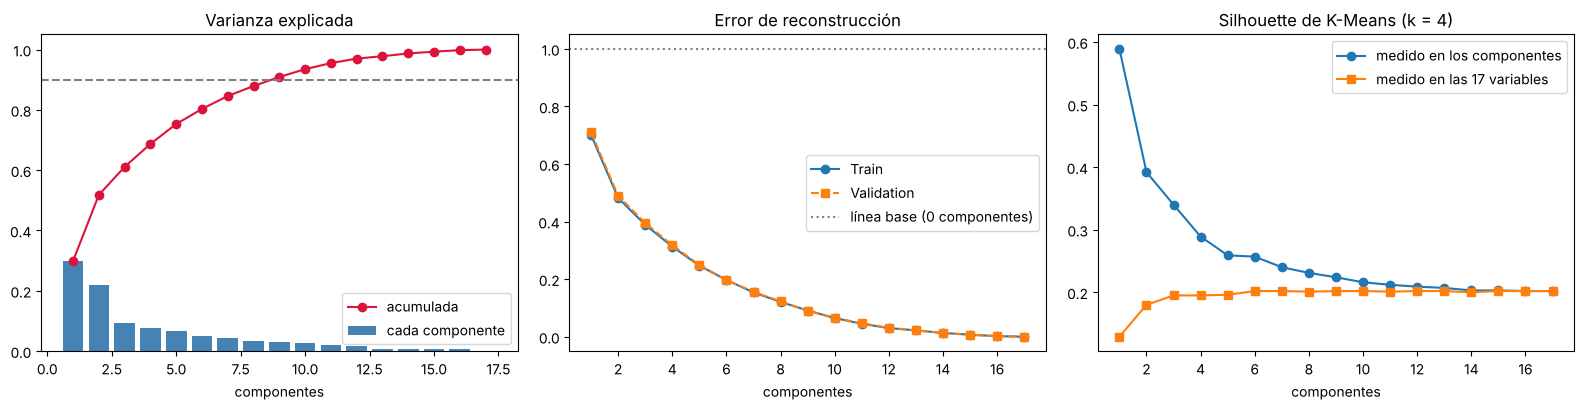

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(tabla_pca["componentes"], pd.Series(PCA().fit(X_train).explained_variance_ratio_), color="steelblue", label="cada componente")
ax[0].plot(tabla_pca["componentes"], tabla_pca["varianza_acum"], marker="o", color="crimson", label="acumulada")
ax[0].axhline(0.9, color="gray", ls="--"); ax[0].set(title="Varianza explicada", xlabel="componentes"); ax[0].legend()
ax[1].plot(tabla_pca["componentes"], tabla_pca["error_train"], marker="o", label="Train")
ax[1].plot(tabla_pca["componentes"], tabla_pca["error_val"], marker="s", ls="--", label="Validation")
ax[1].axhline(1, color="gray", ls=":", label="línea base (0 componentes)"); ax[1].set(title="Error de reconstrucción", xlabel="componentes"); ax[1].legend()
ax[2].plot(tabla_pca["componentes"], tabla_pca["silhouette_en_componentes"], marker="o", label="medido en los componentes")
ax[2].plot(tabla_pca["componentes"], tabla_pca["silhouette_en_17_variables"], marker="s", label="medido en las 17 variables")
ax[2].set(title="Silhouette de K-Means (k = 4)", xlabel="componentes"); ax[2].legend()
plt.tight_layout(); plt.show()

**Lee los tres gráficos.**

1. **Varianza.** Los dos primeros componentes explican cerca del 52 %; para llegar al **90 %** hacen falta **9**. Los últimos componentes casi no aportan: las 17 variables tienen mucha información repetida.
2. **Error de reconstrucción.** Baja de 1 (línea base) a 0 al usar los 17. Train y Validation van juntos con cualquier número de componentes: PCA **no memoriza**.
3. **Silhouette.** Medido en los propios componentes, parece que con 1 o 2 componentes los grupos son mucho mejores (0,59 y 0,39). Es **la trampa**: en el espacio común de las 17 variables, esos mismos grupos valen 0,13 y 0,18, **peor** que agrupar con todo (0,20). Desde unos 6 componentes, los grupos son tan buenos como con las 17 variables. Reducir a 2 dimensiones sirve para **ver** los datos, no para agrupar mejor.

## A.10 Resultado final de la Parte A

- Para **resumir** los 17 indicadores sin perder casi nada: **9 componentes** (90 % de la varianza), con error de reconstrucción igual en Train y Validation.
- Para **visualizar**: 2 componentes, que se interpretan como «compra» (PC1) y «deuda y efectivo» (PC2).

Veamos el mapa de los clientes en PC1–PC2, coloreado con los 4 segmentos de K-Means:

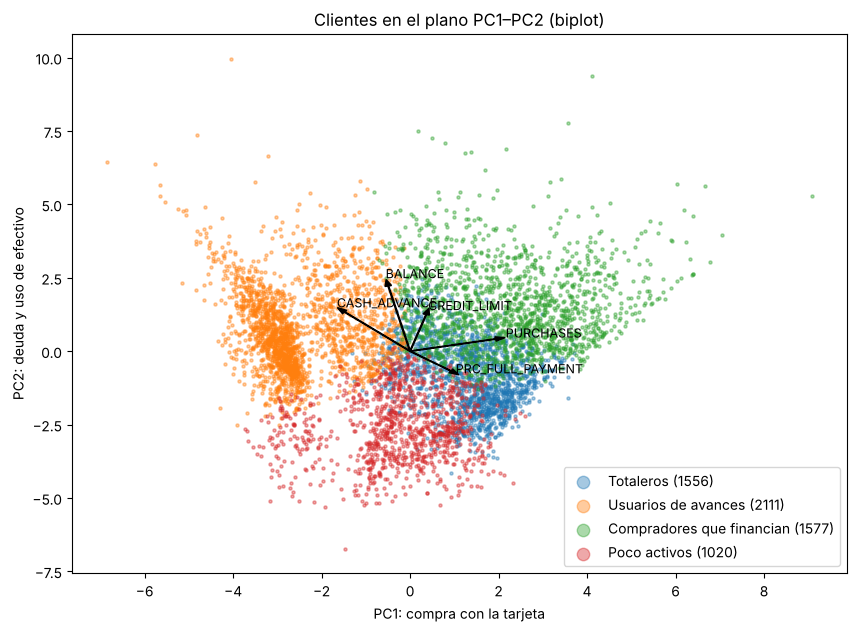

In [19]:
km17 = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X_train)     # segmentos con las 17 variables
perfil = pd.DataFrame(X_train, columns=VARS17).groupby(km17.labels_).mean()
# Nombres con la regla del Día 4
pend = list(perfil.index); NOMBRES = {}
for var, nom in [("PRC_FULL_PAYMENT", "Totaleros"), ("CASH_ADVANCE", "Usuarios de avances"), ("PURCHASES", "Compradores que financian")]:
    s = perfil.loc[pend, var].idxmax(); NOMBRES[s] = nom; pend.remove(s)
NOMBRES[pend[0]] = "Poco activos"

fig, ax = plt.subplots(figsize=(10, 7))
for seg, nom in NOMBRES.items():
    m = km17.labels_ == seg
    ax.scatter(Z_train[m, 0], Z_train[m, 1], s=5, alpha=0.4, label=f"{nom} ({m.sum()})")
for var in ["PURCHASES", "CASH_ADVANCE", "BALANCE", "PRC_FULL_PAYMENT", "CREDIT_LIMIT"]:
    dx, dy = cargas.loc[var] * 5                                         # flechas: hacia dónde crece cada variable
    ax.arrow(0, 0, dx, dy, color="black", width=0.02, head_width=0.15); ax.text(dx * 1.12, dy * 1.12, var, fontsize=9)
ax.set(xlabel="PC1: compra con la tarjeta", ylabel="PC2: deuda y uso de efectivo", title="Clientes en el plano PC1–PC2 (biplot)")
ax.legend(markerscale=4); plt.show()

**Cómo leer el biplot.** Cada punto es un cliente; las flechas indican hacia dónde **crece** cada variable original. Los **totaleros** quedan hacia donde apunta `PRC_FULL_PAYMENT`; los **usuarios de avances**, a la izquierda (compran poco) y arriba (deuda y efectivo); los **compradores que financian**, a la derecha y arriba; los **poco activos**, abajo. Lo que en el Día 4 era un mapa de calor de 9 variables, aquí se ve en un solo plano.

**Un cliente nuevo** se ubica en el mapa con los mismos pasos: logaritmo → `escalador.transform` → `pca2.transform`.

In [20]:
nuevo = pd.DataFrame([cc[VARS17].median()], index=["cliente mediano"])      # un cliente «típico»
nuevo.loc["gran comprador"] = nuevo.loc["cliente mediano"]
nuevo.loc["gran comprador", ["PURCHASES", "INSTALLMENTS_PURCHASES", "PURCHASES_FREQUENCY", "PURCHASES_TRX"]] = [5000, 3000, 1.0, 80]
coords = pca2.transform(escalador.transform(preparar_cc(nuevo)))
pd.DataFrame(coords.round(2), index=nuevo.index, columns=["PC1", "PC2"])

,PC1,PC2
cliente mediano,0.42,-0.32
gran comprador,2.52,0.47


El «gran comprador» se mueve a la **derecha** del mapa (PC1 alto), como esperábamos. **Recuerda:** PCA no mira ninguna respuesta; resume variables. Si lo que queremos es **predecir** algo, la pregunta correcta es otra: ¿qué variables ayudan a predecir? Eso es la Parte B.

# Parte B · Selección de variables con BankChurners

**El problema.** Un banco quiere anticipar qué clientes **abandonarán** la tarjeta (16 % lo hace). Tenemos 19 columnas de cada cliente y, al codificar las categorías, llegan a 37. ¿Todas ayudan? ¿Sobran algunas? ¿Pueden **estorbar**?

## B.1 Mirar los datos

In [21]:
churn = pd.read_csv(DATA_DIR / "BankChurners.csv")
print("Filas y columnas:", churn.shape)
churn.iloc[:, :21].head()

Filas y columnas: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


| Grupo | Columnas |
|---|---|
| Identificador | `CLIENTNUM` (no predice nada) |
| **Respuesta** | `Attrition_Flag`: «Attrited Customer» (abandonó) o «Existing Customer» |
| Perfil (categorías) | `Gender`, `Education_Level`, `Marital_Status`, `Income_Category`, `Card_Category` |
| Perfil (números) | `Customer_Age`, `Dependent_count`, `Months_on_book` (antigüedad) |
| Relación con el banco | `Total_Relationship_Count` (productos), `Months_Inactive_12_mon`, `Contacts_Count_12_mon` |
| Uso de la tarjeta | `Credit_Limit`, `Total_Revolving_Bal` (saldo), `Avg_Open_To_Buy` (cupo libre), `Avg_Utilization_Ratio`, `Total_Trans_Amt` y `Total_Trans_Ct` (monto y número de transacciones en 12 meses), `Total_Amt_Chng_Q4_Q1` y `Total_Ct_Chng_Q4_Q1` (cambio entre trimestres) |
| **Fuga** | Las dos columnas `Naive_Bayes_Classifier_...`: predicciones de otro modelo que **ya conocía la respuesta** |

## B.2 Entender y graficar

Abandonan: 16.1% de 10127 clientes


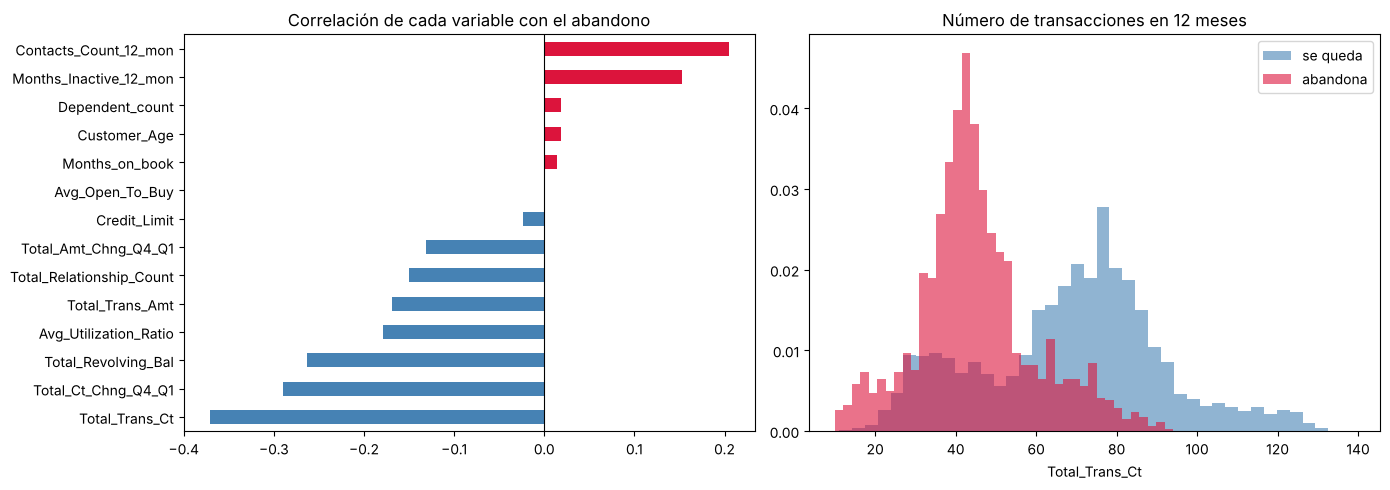

In [22]:
y_ch = (churn["Attrition_Flag"] == "Attrited Customer").astype(int)       # 1 = abandonó
print(f"Abandonan: {y_ch.mean():.1%} de {len(y_ch)} clientes")
num_ch = churn.select_dtypes("number").drop(columns=["CLIENTNUM"]).iloc[:, :14]   # las 14 numéricas (sin las Naive_Bayes)
corr_y = num_ch.corrwith(y_ch).sort_values()                                 # correlación de cada una con el abandono
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
corr_y.plot(kind="barh", ax=ax[0], color=["steelblue" if v < 0 else "crimson" for v in corr_y])
ax[0].set_title("Correlación de cada variable con el abandono"); ax[0].axvline(0, color="black", lw=0.8)
for clase, color in [(0, "steelblue"), (1, "crimson")]:
    ax[1].hist(churn.loc[y_ch == clase, "Total_Trans_Ct"], bins=40, alpha=0.6, color=color, density=True,
               label="se queda" if clase == 0 else "abandona")
ax[1].set(title="Número de transacciones en 12 meses", xlabel="Total_Trans_Ct"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretación.** Las variables de **actividad** (número de transacciones, cambio de transacciones entre trimestres, saldo) tienen la correlación más fuerte (negativa: más actividad, menos abandono). Edad, dependientes o antigüedad casi no se relacionan. En el histograma, quienes abandonan hacen muchas menos transacciones. Ya intuimos que **pocas variables cargan casi toda la información**.

## B.3 Limpiar y preparar, paso a paso

**Paso 1: quitar el identificador y la fuga.** Las columnas `Naive_Bayes_...` se calcularon conociendo la respuesta; si las dejamos, cualquier selector las elegirá primero y el modelo «adivinará» con datos que en la vida real no tendríamos.

In [23]:
FUGA = [c for c in churn.columns if c.startswith("Naive_Bayes")]
X_ch = churn.drop(columns=["CLIENTNUM", "Attrition_Flag"] + FUGA)
print("Columnas que quedan:", X_ch.shape[1])

Columnas que quedan: 19


**Paso 2: One-Hot de las 5 categorías.** Cada categoría se convierte en columnas de 0 y 1 (una por valor). Así pasamos de 19 a 37 columnas.

In [24]:
CATS = ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]
print("Antes:"); print(X_ch[CATS].head(3))
X_ch = pd.get_dummies(X_ch, columns=CATS, dtype=int)          # One-Hot: una columna 0/1 por categoría
print("\nDespués: ", X_ch.shape[1], "columnas. Por ejemplo:")
print(X_ch.filter(like="Income_Category").head(3))

Antes:
  Gender Education_Level Marital_Status Income_Category Card_Category
0      M     High School        Married     $60K - $80K          Blue
1      F        Graduate         Single  Less than $40K          Blue
2      M        Graduate        Married    $80K - $120K          Blue

Después:  37 columnas. Por ejemplo:
   Income_Category_$120K +  Income_Category_$40K - $60K  Income_Category_$60K - $80K  Income_Category_$80K - $120K  Income_Category_Less than $40K  \
0                        0                            0                            1                             0                               0   
1                        0                            0                            0                             0                               1   
2                        0                            0                            0                             1                               0   

   Income_Category_Unknown  
0                        0  
1                

*Nota:* `get_dummies` sobre toda la tabla está bien aquí porque solo crea columnas (no aprende promedios). Lo que sí aprende —escalar y seleccionar— se ajustará **solo con Train**.

**Paso 3: dividir** en Train (70 %), Validation (15 %) y Test (15 %), estratificado para conservar el 16 % de abandonos en cada parte.

In [25]:
X_tr_ch, X_tmp, y_tr_ch, y_tmp = train_test_split(X_ch, y_ch, test_size=0.30, random_state=42, stratify=y_ch)
X_va_ch, X_te_ch, y_va_ch, y_te_ch = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)
print("Train:", X_tr_ch.shape, "| Validation:", X_va_ch.shape, "| Test:", X_te_ch.shape)
print("Abandono en cada parte:", round(y_tr_ch.mean(), 3), round(y_va_ch.mean(), 3), round(y_te_ch.mean(), 3))

Train: (7088, 37) | Validation: (1519, 37) | Test: (1520, 37)
Abandono en cada parte: 0.161 0.161 0.161


## B.4 Línea base: usar todas las variables

Dos referencias: la línea base «tonta» (predecir siempre «se queda») y los modelos del Día 3 **con las 37 columnas**: KNN (15 vecinos, con escalado) y Random Forest (200 árboles, profundidad 12).

In [26]:
base = DummyClassifier(strategy="most_frequent").fit(X_tr_ch, y_tr_ch)
knn_todas = Pipeline([("escalar", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=15))]).fit(X_tr_ch, y_tr_ch)
rf_todas = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1).fit(X_tr_ch, y_tr_ch)
res_base = [evaluar(base, "Siempre «se queda»", X_tr_ch, y_tr_ch, X_va_ch, y_va_ch),
            evaluar(knn_todas, "KNN, 37 columnas", X_tr_ch, y_tr_ch, X_va_ch, y_va_ch),
            evaluar(rf_todas, "Random Forest, 37 columnas", X_tr_ch, y_tr_ch, X_va_ch, y_va_ch)]
pd.DataFrame(res_base).set_index("modelo").round(3)

,f1_train,f1_val,brecha
modelo,,,
Siempre «se queda»,0.000,0.000,0.000
"KNN, 37 columnas",0.392,0.240,0.153
"Random Forest, 37 columnas",0.982,0.832,0.150


**¡Sorpresa!** El Random Forest funciona bien con las 37 columnas, pero **KNN se desploma**: su F1 en Validation es muy bajo. ¿Por qué? KNN decide por **distancia**, y la distancia suma las diferencias de **todas** las columnas. Las 23 columnas de 0/1 (sexo, educación, ingresos…) casi no tienen relación con el abandono, pero aportan tanto a la distancia como las importantes: los «vecinos» dejan de parecerse en lo que importa. Es la **maldición de la dimensionalidad**: con muchas columnas irrelevantes, todo queda «igual de lejos».

El árbol, en cambio, elige en cada pregunta la mejor variable e **ignora** las demás: ya hace su propia selección.

## B.5 Selección a mano: tres familias de métodos

| Familia | Cómo decide | Ejemplo en scikit-learn | Ventaja | Riesgo |
|---|---|---|---|---|
| **Filtro** | Mide cada variable **sola** frente a `y` (correlación, prueba F, información mutua) y se queda con las mejores | `SelectKBest` | Rápido, no depende del modelo | No ve combinaciones ni repeticiones |
| **Envoltura** (*wrapper*) | Entrena el modelo y quita, una a una, la variable menos útil | `RFE` | Tiene en cuenta el modelo | Lento |
| **Embebido** | El propio modelo mide la importancia mientras aprende (árboles, Lasso) | `SelectFromModel` | Un solo entrenamiento | Depende de ese modelo |

**El filtro más simple, a mano: la correlación** de una variable con la respuesta.

$$r = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2}\sqrt{\sum (y_i-\bar y)^2}}$$

In [27]:
x = X_tr_ch["Total_Trans_Ct"].values.astype(float); yv = y_tr_ch.values.astype(float)
num = ((x - x.mean()) * (yv - yv.mean())).sum()                          # cuánto varían juntas
den = np.sqrt(((x - x.mean()) ** 2).sum()) * np.sqrt(((yv - yv.mean()) ** 2).sum())
print(f"Correlación a mano de Total_Trans_Ct con el abandono: {num:.0f} / {den:.0f} = {num / den:.3f}")
print("Con pandas:", round(np.corrcoef(x, yv)[0, 1], 3))

ranking = X_tr_ch.corrwith(y_tr_ch).abs().sort_values(ascending=False)   # |correlación| de las 37, solo con Train
print("\nLas 8 variables con mayor |correlación| (Train):"); print(ranking.head(8).round(3))
print("\nLas 5 con menor:"); print(ranking.tail(5).round(3))

Correlación a mano de Total_Trans_Ct con el abandono: -23353 / 61502 = -0.380
Con pandas: -0.38

Las 8 variables con mayor |correlación| (Train):
Total_Trans_Ct              0.380
Total_Ct_Chng_Q4_Q1         0.292
Total_Revolving_Bal         0.267
Contacts_Count_12_mon       0.208
Avg_Utilization_Ratio       0.187
Total_Trans_Amt             0.177
Total_Relationship_Count    0.159
Months_Inactive_12_mon      0.156
dtype: float64

Las 5 con menor:
Card_Category_Platinum        0.006
Education_Level_Uneducated    0.006
Avg_Open_To_Buy               0.006
Months_on_book                0.003
Card_Category_Blue            0.000
dtype: float64


**La información mutua** es un filtro más general: mide cuánto **reduce la incertidumbre sobre `y`** conocer la variable, aunque la relación no sea una línea recta. Vale 0 si la variable no dice nada sobre `y`.

**El método de envoltura (RFE), a mano:** entrenar el modelo con todas → quitar la variable menos importante → volver a entrenar → … hasta dejar las `k` pedidas. Veamos las primeras vueltas con un árbol pequeño (2 variables quitadas por vuelta):

In [28]:
from sklearn.tree import DecisionTreeClassifier
restantes = list(X_tr_ch.columns)
for vuelta in range(1, 4):
    arbol = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_tr_ch[restantes], y_tr_ch)
    imp = pd.Series(arbol.feature_importances_, index=restantes).sort_values()
    quitar = list(imp.index[:2])                                      # las 2 menos importantes
    restantes = [c for c in restantes if c not in quitar]
    print(f"Vuelta {vuelta}: quito {quitar} → quedan {len(restantes)}")

Vuelta 1: quito ['Customer_Age', 'Dependent_count'] → quedan 35
Vuelta 2: quito ['Months_on_book', 'Credit_Limit'] → quedan 33
Vuelta 3: quito ['Education_Level_College', 'Education_Level_High School'] → quedan 31


## B.6 La versión simple con scikit-learn

`SelectKBest` es un filtro: calcula una puntuación por variable con Train y deja las `k` mejores. Lo ponemos **dentro de un Pipeline**, después del escalado y antes del modelo: así la selección se aprende solo con Train y se aplica igual a Validation.

In [29]:
def mi(X, y):
    # información mutua con semilla fija, para que el resultado sea reproducible
    return mutual_info_classif(X, y, random_state=0)

knn_5 = Pipeline([("escalar", StandardScaler()),                       # 1) estandarizar
                  ("seleccionar", SelectKBest(score_func=mi, k=5)),    # 2) quedarse con las 5 de mayor información mutua
                  ("knn", KNeighborsClassifier(n_neighbors=15))])      # 3) KNN con esas 5
knn_5.fit(X_tr_ch, y_tr_ch)                                            # todo se aprende con Train
elegidas = X_tr_ch.columns[knn_5.named_steps["seleccionar"].get_support()]
print("Variables elegidas:", list(elegidas))
puntajes = pd.Series(knn_5.named_steps["seleccionar"].scores_, index=X_tr_ch.columns).sort_values(ascending=False)
print("\nInformación mutua (las 8 mayores):"); print(puntajes.head(8).round(3))

Variables elegidas: ['Total_Revolving_Bal', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']

Información mutua (las 8 mayores):
Total_Trans_Amt          0.159
Total_Trans_Ct           0.115
Total_Ct_Chng_Q4_Q1      0.105
Total_Revolving_Bal      0.089
Avg_Utilization_Ratio    0.049
Total_Amt_Chng_Q4_Q1     0.038
Contacts_Count_12_mon    0.022
Avg_Open_To_Buy          0.019
dtype: float64


## B.7 Métricas a mano y con scikit-learn: Train frente a Validation

In [30]:
pred_va = knn_5.predict(X_va_ch)
vn, fp, fn, vp = confusion_matrix(y_va_ch, pred_va).ravel()
print(f"KNN con 5 variables, Validation: VN={vn} FP={fp} FN={fn} VP={vp}")
print(f"A mano: Precision = {vp}/({vp}+{fp}) = {vp/(vp+fp):.3f} | Recall = {vp}/({vp}+{fn}) = {vp/(vp+fn):.3f} | F1 = 2·{vp}/(2·{vp}+{fp}+{fn}) = {2*vp/(2*vp+fp+fn):.3f}")
print("scikit-learn:", {k: round(v, 3) for k, v in metricas(y_va_ch, pred_va).items()})
res_sel = res_base + [evaluar(knn_5, "KNN, 5 variables (información mutua)", X_tr_ch, y_tr_ch, X_va_ch, y_va_ch)]
pd.DataFrame(res_sel).set_index("modelo").round(3)

KNN con 5 variables, Validation: VN=1236 FP=39 FN=74 VP=170
A mano: Precision = 170/(170+39) = 0.813 | Recall = 170/(170+74) = 0.697 | F1 = 2·170/(2·170+39+74) = 0.751
scikit-learn: {'accuracy': 0.926, 'precision': 0.813, 'recall': 0.697, 'f1': 0.751}


,f1_train,f1_val,brecha
modelo,,,
Siempre «se queda»,0.000,0.000,0.000
"KNN, 37 columnas",0.392,0.240,0.153
"Random Forest, 37 columnas",0.982,0.832,0.150
"KNN, 5 variables (información mutua)",0.771,0.751,0.021


**Interpretación.** Con solo 5 de 37 columnas, el F1 de KNN en Validation **se triplica** y la brecha con Train es pequeña. Menos columnas, pero las correctas: los vecinos vuelven a parecerse en lo que importa (actividad de la tarjeta).

## B.8 Los hiperparámetros de la selección, uno por uno

| Herramienta | Hiperparámetro | Qué controla |
|---|---|---|
| `SelectKBest` | `score_func` | Cómo puntuar cada variable: `f_classif` (prueba F, relación lineal), `mutual_info_classif` (cualquier relación) |
| | `k` | Cuántas variables dejar (`"all"` = todas) |
| `RFE` | `estimator` | El modelo que mide la importancia en cada vuelta |
| | `n_features_to_select` | Cuántas dejar al final |
| | `step` | Cuántas quitar en cada vuelta (más grande = más rápido, menos fino) |
| `SelectFromModel` | `estimator` | Modelo que da las importancias (por ejemplo, un Random Forest) |
| | `threshold` | Umbral: deja las variables con importancia mayor a, por ejemplo, `"mean"` (el promedio) |
| | `max_features` | Máximo de variables a dejar |

Comparemos los tres métodos pidiendo 5 variables:

In [31]:
selectores = {
    "Filtro: prueba F": SelectKBest(score_func=f_classif, k=5),
    "Filtro: información mutua": SelectKBest(score_func=mi, k=5),
    "Envoltura: RFE con árbol": RFE(estimator=DecisionTreeClassifier(max_depth=5, random_state=42), n_features_to_select=5, step=2),
    "Embebido: importancia de RF": SelectFromModel(RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
                                                   threshold=-np.inf, max_features=5)}
filas = []
for nombre, sel in selectores.items():
    p = Pipeline([("escalar", StandardScaler()), ("seleccionar", sel), ("knn", KNeighborsClassifier(n_neighbors=15))]).fit(X_tr_ch, y_tr_ch)
    fila = evaluar(p, nombre, X_tr_ch, y_tr_ch, X_va_ch, y_va_ch)
    fila["variables"] = ", ".join(X_tr_ch.columns[p.named_steps["seleccionar"].get_support()])
    filas.append(fila)
pd.DataFrame(filas).set_index("modelo").round(3)

,f1_train,f1_val,brecha,variables
modelo,,,,
Filtro: prueba F,0.671,0.635,0.037,"Contacts_Count_12_mon, Total_Revolving_Bal, To..."
Filtro: información mutua,0.771,0.751,0.021,"Total_Revolving_Bal, Total_Trans_Amt, Total_Tr..."
Envoltura: RFE con árbol,0.781,0.759,0.022,"Total_Relationship_Count, Total_Revolving_Bal,..."
Embebido: importancia de RF,0.771,0.751,0.021,"Total_Revolving_Bal, Total_Trans_Amt, Total_Tr..."


**Lee la tabla.** La prueba F (relación lineal) elige variables distintas a las de los otros métodos y obtiene un F1 menor; información mutua, RFE y la importancia del bosque coinciden en buena parte (transacciones, saldo, cambio entre trimestres) y dan resultados parecidos. Cuando métodos distintos eligen las mismas variables, hay buena señal de que **esas** son las que importan.

## B.9 Probar combinaciones con un `for`: ¿cuántas variables?

Recorremos `k` (número de variables) con KNN y con Random Forest, siempre dentro del Pipeline, y comparamos con la línea base de las 37 columnas.

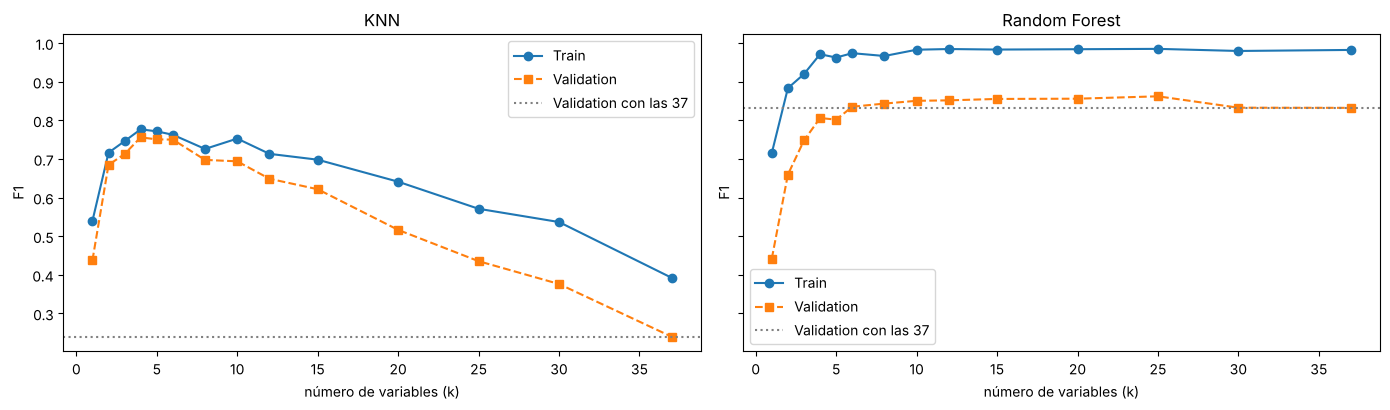

f1_train               f1_val              
modelo      KNN Random Forest    KNN Random Forest
k                                                 
1         0.539         0.715  0.437         0.442
2         0.716         0.883  0.685         0.659
3         0.746         0.920  0.713         0.748
4         0.777         0.971  0.756         0.806
5         0.771         0.962  0.751         0.802
6         0.763         0.974  0.750         0.835
8         0.726         0.966  0.697         0.843
10        0.753         0.983  0.694         0.850
12        0.713         0.984  0.649         0.852
15        0.698         0.983  0.622         0.855
20        0.641         0.984  0.516         0.856
25        0.571         0.985  0.435         0.862
30        0.537         0.979  0.376         0.833
37        0.392         0.982  0.240         0.832

In [32]:
filas = []
for k in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 37]:
    for nombre, modelo in [("KNN", KNeighborsClassifier(n_neighbors=15)),
                           ("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1))]:
        p = Pipeline([("escalar", StandardScaler()), ("seleccionar", SelectKBest(score_func=mi, k=k)), ("modelo", modelo)])
        p.fit(X_tr_ch, y_tr_ch)
        fila = evaluar(p, nombre, X_tr_ch, y_tr_ch, X_va_ch, y_va_ch); fila["k"] = k
        filas.append(fila)
curva = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for i, nombre in enumerate(["KNN", "Random Forest"]):
    t = curva[curva["modelo"] == nombre]
    ax[i].plot(t["k"], t["f1_train"], marker="o", label="Train"); ax[i].plot(t["k"], t["f1_val"], marker="s", ls="--", label="Validation")
    ax[i].axhline(t[t["k"] == 37]["f1_val"].iloc[0], color="gray", ls=":", label="Validation con las 37")
    ax[i].set(title=nombre, xlabel="número de variables (k)", ylabel="F1"); ax[i].legend()
plt.tight_layout(); plt.show()
curva.pivot(index="k", columns="modelo", values=["f1_train", "f1_val"]).round(3)

**Interpretación.**

- **KNN** mejora mucho al pasar de 37 a pocas variables: su mejor zona está entre 4 y 6. Con más de 10 empieza a caer porque entran columnas irrelevantes.
- **Random Forest** casi no cambia a partir de unas 8–10 variables, y con las 37 está apenas un poco peor que con 15–20. El bosque ya ignora lo que no sirve; la selección le ayuda poco, pero simplifica el modelo.
- Con muy pocas variables (1 o 2) los dos empeoran: quitamos información útil.

**Una advertencia: la selección también puede tener fuga.** Si dejamos las columnas `Naive_Bayes` (que conocían la respuesta), el selector las elige primero:

In [33]:
X_fuga = pd.get_dummies(churn.drop(columns=["CLIENTNUM", "Attrition_Flag"]), columns=CATS, dtype=int)
Xf_tr, Xf_va = X_fuga.loc[X_tr_ch.index], X_fuga.loc[X_va_ch.index]
p = Pipeline([("escalar", StandardScaler()), ("seleccionar", SelectKBest(score_func=mi, k=5)), ("knn", KNeighborsClassifier(n_neighbors=15))]).fit(Xf_tr, y_tr_ch)
print("Elegidas con la fuga:", [c[:40] for c in Xf_tr.columns[p.named_steps["seleccionar"].get_support()]])
print("F1 en Validation:", round(f1_score(y_va_ch, p.predict(Xf_va)), 3), "← demasiado bueno para ser cierto")

Elegidas con la fuga: ['Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Naive_Bayes_Classifier_Attrition_Flag_Ca', 'Naive_Bayes_Classifier_Attrition_Flag_Ca']
F1 en Validation: 1.0 ← demasiado bueno para ser cierto


Un F1 casi perfecto es una alarma, no un éxito: el selector «descubrió» columnas que contienen la respuesta. **La selección no protege contra la fuga; hay que limpiarla antes.**

## B.10 Resultado final de la Parte B

In [34]:
mejor_knn = curva[curva["modelo"] == "KNN"].sort_values("f1_val", ascending=False).iloc[0]
mejor_rf = curva[curva["modelo"] == "Random Forest"].sort_values("f1_val", ascending=False).iloc[0]
K_KNN, K_RF = int(mejor_knn["k"]), int(mejor_rf["k"])
print(f"KNN:           mejor k = {K_KNN:2d} → F1 Validation {mejor_knn['f1_val']:.3f} (con las 37: {curva[(curva.modelo=='KNN') & (curva.k==37)].f1_val.iloc[0]:.3f})")
print(f"Random Forest: mejor k = {K_RF:2d} → F1 Validation {mejor_rf['f1_val']:.3f} (con las 37: {curva[(curva.modelo=='Random Forest') & (curva.k==37)].f1_val.iloc[0]:.3f})")

KNN:           mejor k =  4 → F1 Validation 0.756 (con las 37: 0.240)
Random Forest: mejor k = 25 → F1 Validation 0.862 (con las 37: 0.832)


**Conclusión.** Seleccionar variables es **indispensable para KNN** (y para todo modelo basado en distancias) y **opcional para el bosque**. Las variables que sobreviven son siempre las de actividad: número y monto de transacciones, cambio entre trimestres y saldo. Las variables demográficas casi no ayudan a predecir el abandono.

# Parte C · Ingeniería de características

**La idea.** Seleccionar es **quitar** columnas; PCA es **combinar** columnas automáticamente. La ingeniería de características es **crear** columnas nuevas usando lo que sabemos del problema. Un modelo solo ve números; si nosotros sabemos que «gasto por transacción» o «uso del cupo» importan, podemos dárselos ya calculados.

| Tipo | Ejemplo | Para qué |
|---|---|---|
| **Cociente** | monto / número de transacciones = gasto promedio por compra | Comparar clientes de distinto tamaño |
| **Logaritmo** | log(1 + monto) | Montos muy asimétricos (Día 4) |
| **Indicador 0/1** | ¿tiene saldo pendiente? | Separar «nada» de «algo» |
| **Interacción o potencia** | tasa × cuota, (transacciones)² | Efectos combinados o curvos |
| **Agrupar en tramos** | edad en rangos | Relaciones por escalones |
| **Fechas** | mes, día de la semana, rezagos | Series de tiempo (Día 7) |

**Regla de oro:** una variable nueva solo puede usar información **disponible al momento de predecir** y, si aprende algo (un promedio, una mediana), se aprende **solo con Train**.

## C.1 Crear variables en BankChurners, a mano

In [35]:
def crear_variables(df):
    # Recibe la tabla de BankChurners y devuelve la misma tabla con 4 columnas nuevas
    d = df.copy()
    d["monto_por_transaccion"] = d["Total_Trans_Amt"] / d["Total_Trans_Ct"]                  # gasto promedio por compra
    d["tiene_saldo"] = (d["Total_Revolving_Bal"] > 0).astype(int)                           # 1 si debe algo
    d["contactos_por_inactividad"] = d["Contacts_Count_12_mon"] / (d["Months_Inactive_12_mon"] + 1)   # cuánto llama estando inactivo
    d["log_monto"] = np.log1p(d["Total_Trans_Amt"])                                         # monto en escala logarítmica
    return d

c0 = X_tr_ch.iloc[0]                                   # un cliente de Train
print("A mano, primer cliente de Train:")
print(f"  monto_por_transaccion     = {c0.Total_Trans_Amt} / {c0.Total_Trans_Ct} = {c0.Total_Trans_Amt / c0.Total_Trans_Ct:.1f}")
print(f"  tiene_saldo               = ¿{c0.Total_Revolving_Bal} > 0? → {int(c0.Total_Revolving_Bal > 0)}")
print(f"  contactos_por_inactividad = {c0.Contacts_Count_12_mon} / ({c0.Months_Inactive_12_mon} + 1) = {c0.Contacts_Count_12_mon / (c0.Months_Inactive_12_mon + 1):.2f}")
print(f"  log_monto                 = log(1 + {c0.Total_Trans_Amt}) = {np.log1p(c0.Total_Trans_Amt):.2f}")

X_tr_ing, X_va_ing, X_te_ing = crear_variables(X_tr_ch), crear_variables(X_va_ch), crear_variables(X_te_ch)
NUEVAS = ["monto_por_transaccion", "tiene_saldo", "contactos_por_inactividad", "log_monto"]
print("\nDespués (columnas nuevas, primeras filas):"); print(X_tr_ing[["Total_Trans_Amt", "Total_Trans_Ct"] + NUEVAS].head(3).round(2))

A mano, primer cliente de Train:
  monto_por_transaccion     = 7632.0 / 95.0 = 80.3
  tiene_saldo               = ¿1839.0 > 0? → 1
  contactos_por_inactividad = 3.0 / (3.0 + 1) = 0.75
  log_monto                 = log(1 + 7632.0) = 8.94

Después (columnas nuevas, primeras filas):
      Total_Trans_Amt  Total_Trans_Ct  monto_por_transaccion  tiene_saldo  contactos_por_inactividad  log_monto
8948             7632              95                  80.34            1                       0.75       8.94
6665             4809              87                  55.28            1                       0.50       8.48
7119             4286              72                  59.53            1                       0.67       8.36


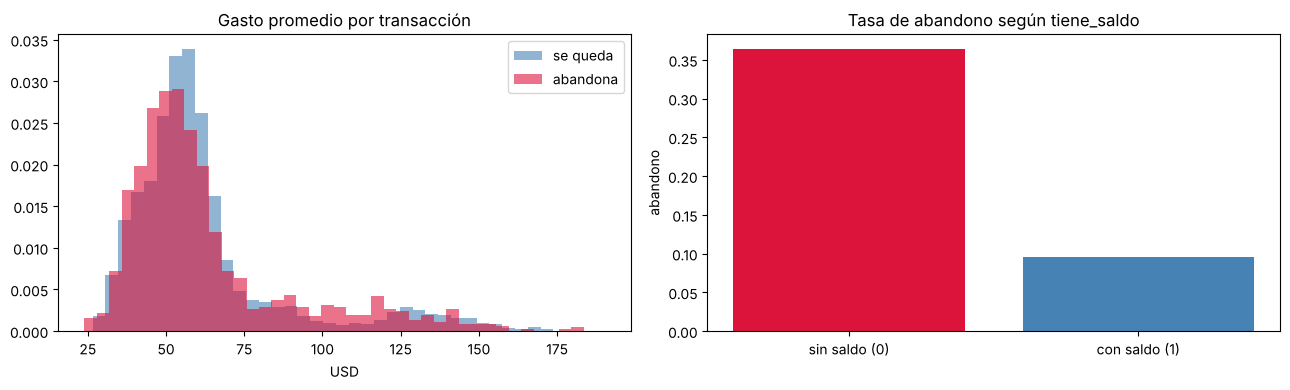

Tasa de abandono: {0: 0.364, 1: 0.095}


In [36]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for clase, color in [(0, "steelblue"), (1, "crimson")]:
    m = y_tr_ch == clase
    ax[0].hist(X_tr_ing.loc[m, "monto_por_transaccion"], bins=40, alpha=0.6, density=True, color=color, label="se queda" if clase == 0 else "abandona")
ax[0].set(title="Gasto promedio por transacción", xlabel="USD"); ax[0].legend()
tasa = y_tr_ch.groupby(X_tr_ing["tiene_saldo"]).mean()
ax[1].bar(["sin saldo (0)", "con saldo (1)"], tasa.values, color=["crimson", "steelblue"])
ax[1].set(title="Tasa de abandono según tiene_saldo", ylabel="abandono")
plt.tight_layout(); plt.show()
print("Tasa de abandono:", tasa.round(3).to_dict())

**Interpretación.** Los clientes **sin saldo pendiente** abandonan mucho más (≈ 36 %) que los que tienen saldo (≈ 9 %): una sola columna de 0/1 separa bastante. El gasto promedio por compra también tiene formas distintas en los dos grupos.

## C.2 Versión simple: ¿mejoran los modelos?

Comparamos, en Train y Validation, los modelos de la Parte B con y sin las 4 variables nuevas.

In [37]:
top = list(elegidas)                                         # las 5 variables elegidas en B.6
pruebas = [("KNN, 5 elegidas", top, KNeighborsClassifier(n_neighbors=15)),
           ("KNN, 5 elegidas + 4 nuevas", top + NUEVAS, KNeighborsClassifier(n_neighbors=15)),
           ("Random Forest, 37 columnas", list(X_tr_ch.columns), RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)),
           ("Random Forest, 37 + 4 nuevas", list(X_tr_ing.columns), RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1))]
filas = []
for nombre, cols, modelo in pruebas:
    p = Pipeline([("escalar", StandardScaler()), ("modelo", modelo)]).fit(X_tr_ing[cols], y_tr_ch)
    filas.append(evaluar(p, nombre, X_tr_ing[cols], y_tr_ch, X_va_ing[cols], y_va_ch))
pd.DataFrame(filas).set_index("modelo").round(3)

,f1_train,f1_val,brecha
modelo,,,
"KNN, 5 elegidas",0.771,0.751,0.021
"KNN, 5 elegidas + 4 nuevas",0.794,0.780,0.014
"Random Forest, 37 columnas",0.982,0.832,0.150
"Random Forest, 37 + 4 nuevas",0.984,0.870,0.114


**Interpretación.** Los dos modelos mejoran en Validation: KNN pasa de 0,751 a 0,780 y el Random Forest de 0,832 a 0,870, con menos brecha. Les damos ya calculado algo que no podían «ver» directamente: el cociente entre monto y número de transacciones (gasto por compra) y el indicador de saldo. Un árbol podría aproximar un cociente con muchas preguntas, pero dárselo hecho es más eficiente.

## C.3 Interacciones y potencias: `PolynomialFeatures`

Crea automáticamente los cuadrados y productos de las columnas. Con dos variables $a$ y $b$ y grado 2: $[a,\ b,\ a^2,\ a\,b,\ b^2]$.

| Hiperparámetro | Qué controla | Por defecto |
|---|---|---|
| `degree` | Grado máximo: 2 crea cuadrados y productos de dos; 3 agrega cubos y productos de tres | 2 |
| `interaction_only` | `True`: solo productos entre variables distintas ($a\,b$), sin cuadrados | `False` |
| `include_bias` | Agrega una columna de unos | `True` |

In [38]:
dos = X_tr_ch[["Total_Trans_Ct", "Total_Ct_Chng_Q4_Q1"]].head(3)
poli = PolynomialFeatures(degree=2, include_bias=False).fit(dos)
print("Antes:"); print(dos)
print("\nDespués (grado 2):"); print(pd.DataFrame(poli.transform(dos), columns=poli.get_feature_names_out()).round(2))
print(f"\nA mano, fila 1: {dos.iloc[0, 0]}² = {dos.iloc[0, 0] ** 2}; {dos.iloc[0, 0]} × {dos.iloc[0, 1]} = {dos.iloc[0, 0] * dos.iloc[0, 1]:.2f}")

Antes:
      Total_Trans_Ct  Total_Ct_Chng_Q4_Q1
8948              95                0.532
6665              87                0.740
7119              72                0.636

Después (grado 2):
   Total_Trans_Ct  Total_Ct_Chng_Q4_Q1  Total_Trans_Ct^2  Total_Trans_Ct Total_Ct_Chng_Q4_Q1  Total_Ct_Chng_Q4_Q1^2
0            95.0                 0.53            9025.0                               50.54                   0.28
1            87.0                 0.74            7569.0                               64.38                   0.55
2            72.0                 0.64            5184.0                               45.79                   0.40

A mano, fila 1: 95² = 9025; 95 × 0.532 = 50.54


## C.4 Probar combinaciones con un `for`

Con las 5 variables elegidas, probamos grados 1 (sin cambios), 2 y 3, con y sin las 4 variables nuevas, usando KNN. Cuidado: con 9 columnas, grado 3 crea 219 columnas.

In [39]:
filas = []
for usar_nuevas in [False, True]:
    cols = top + (NUEVAS if usar_nuevas else [])
    for grado in [1, 2, 3]:
        p = Pipeline([("poli", PolynomialFeatures(degree=grado, include_bias=False)),   # crear potencias e interacciones
                      ("escalar", StandardScaler()),
                      ("knn", KNeighborsClassifier(n_neighbors=15))]).fit(X_tr_ing[cols], y_tr_ch)
        fila = evaluar(p, f"{'5 + 4 nuevas' if usar_nuevas else '5 elegidas'}, grado {grado}", X_tr_ing[cols], y_tr_ch, X_va_ing[cols], y_va_ch)
        fila["columnas"] = p.named_steps["poli"].n_output_features_
        filas.append(fila)
pd.DataFrame(filas).set_index("modelo").round(3)

,f1_train,f1_val,brecha,columnas
modelo,,,,
"5 elegidas, grado 1",0.771,0.751,0.021,5
"5 elegidas, grado 2",0.769,0.750,0.019,20
"5 elegidas, grado 3",0.772,0.744,0.028,55
"5 + 4 nuevas, grado 1",0.794,0.780,0.014,9
"5 + 4 nuevas, grado 2",0.778,0.748,0.031,54
"5 + 4 nuevas, grado 3",0.766,0.740,0.026,219


**Interpretación.** Las potencias **no** ayudan a KNN: con grado 2 y 3 aparecen decenas o cientos de columnas y volvemos a la maldición de la dimensionalidad de la Parte B. Las 4 variables creadas **con sentido económico** mejoran; las creadas **en masa** empeoran. Más columnas no es mejor: mejores columnas, sí.

## C.5 Ingeniería para clustering: CC GENERAL

En clustering la ingeniería sirve sobre todo para **interpretar**. Tres cocientes con sentido para un banco:

- **Uso del cupo** = saldo / límite de crédito.
- **Pago frente al mínimo** = pagos / pago mínimo (menos de 1: paga menos del mínimo).
- **Compra promedio** = compras / número de compras (0 si no compra).

In [40]:
def crear_variables_cc(df):
    d = df.copy()
    d["uso_cupo"] = (d["BALANCE"] / d["CREDIT_LIMIT"]).clip(upper=1.5)                     # recortamos extremos en 150 %
    d["pago_vs_minimo"] = (d["PAYMENTS"] / d["MINIMUM_PAYMENTS"]).clip(upper=10)
    d["compra_promedio"] = np.where(d["PURCHASES_TRX"] > 0, d["PURCHASES"] / d["PURCHASES_TRX"].replace(0, 1), 0)
    return d

c1 = train_cc.iloc[0]
print(f"A mano, primer cliente: uso_cupo = {c1.BALANCE:.0f} / {c1.CREDIT_LIMIT:.0f} = {c1.BALANCE / c1.CREDIT_LIMIT:.2f};",
      f"pago_vs_minimo = {c1.PAYMENTS:.0f} / {c1.MINIMUM_PAYMENTS:.0f} = {c1.PAYMENTS / c1.MINIMUM_PAYMENTS:.2f}")
cc_ing = crear_variables_cc(train_cc)
cc_ing["segmento"] = pd.Series(km17.labels_, index=train_cc.index).map(NOMBRES)          # segmentos de la Parte A
cc_ing.groupby("segmento")[["uso_cupo", "pago_vs_minimo", "compra_promedio"]].median().round(2)

A mano, primer cliente: uso_cupo = 2144 / 3500 = 0.61; pago_vs_minimo = 12572 / 525 = 23.94


,uso_cupo,pago_vs_minimo,compra_promedio
segmento,,,
Compradores que financian,0.29,4.13,63.89
Poco activos,0.01,2.82,50.08
Totaleros,0.09,2.11,38.40
Usuarios de avances,0.65,1.13,0.00


**Interpretación.** Las variables nuevas **describen** a cada segmento con palabras de negocio: los usuarios de avances usan el 65 % de su cupo y pagan apenas el mínimo (1,1 veces); los poco activos casi no usan cupo (1 %); los compradores que financian usan el 29 % y pagan 4 veces el mínimo. Son las variables que un analista de riesgo mira primero.

## C.6 Resultado final de la Parte C

- Las variables creadas **con conocimiento del problema** (cocientes, indicadores, logaritmos) mejoran a los modelos simples y ayudan a explicar los grupos.
- Las creadas **automáticamente en masa** (potencias de grado 2 o 3) multiplican columnas y empeoran a los modelos basados en distancias.

# Parte D · Comparación final: ¿qué preparación funciona mejor en cada dataset?

Ahora juntamos todo. Para cada dataset probamos las mismas **preparaciones** y elegimos la mejor según la métrica en **Validation**:

| Preparación | Qué hace |
|---|---|
| Todas | Las columnas originales (línea base) |
| Selección | Las `k` mejores por información mutua (`k` elegido en Validation) |
| PCA 90 % | Los componentes necesarios para explicar el 90 % de la varianza |
| Ingeniería | Las originales más las variables creadas |
| Selección + ingeniería | Las `k` mejores entre originales y creadas |

| Dataset | Problema | Modelos | Métrica |
|---|---|---|---|
| BankChurners | Clasificación: abandono | KNN y Random Forest | F1 |
| Credit Risk (Día 3) | Clasificación: impago | KNN y Random Forest | F1 |
| CC GENERAL | Clustering | K-Means (k = 4) | Silhouette en el espacio común de las 17 variables, con el grupo más chico ≥ 5 % |

## D.1 Preparar Credit Risk

La misma limpieza del Día 3 y 4 variables nuevas.

In [41]:
cr = pd.read_csv(DATA_DIR / "credit_risk_dataset.csv")
cr = cr[(cr["person_age"] <= 100) & ~(cr["person_emp_length"] > 60)].drop_duplicates().reset_index(drop=True)   # errores y duplicados
y_cr = cr.pop("loan_status")                                       # 1 = impago
def crear_variables_cr(df):
    d = df.copy()
    d["log_ingreso"] = np.log1p(d["person_income"])                                  # ingreso en escala logarítmica
    d["interes_anual"] = d["loan_amnt"] * d["loan_int_rate"] / 100                    # cuánto paga de interés al año
    d["presion_cuota"] = d["loan_percent_income"] * d["loan_int_rate"]                # peso de la cuota × tasa
    d["antiguedad_relativa"] = d["person_emp_length"] / d["person_age"]               # años trabajando / edad
    return d
CAT_CR = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
idx_tr, idx_tmp = train_test_split(cr.index, test_size=0.30, random_state=42, stratify=y_cr)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, random_state=42, stratify=y_cr[idx_tmp])
print("Préstamos:", len(cr), "| impago:", round(y_cr.mean(), 3), "| Train/Val/Test:", len(idx_tr), len(idx_va), len(idx_te))

def prep_cr(columnas_num):
    # imputar mediana + escalar los números; One-Hot de las categorías. Se ajusta con Train dentro del Pipeline
    return ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), columnas_num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_CR)])
NUM_CR = [c for c in cr.columns if c not in CAT_CR]
cr_ing = crear_variables_cr(cr)
NUM_CR_ING = [c for c in cr_ing.columns if c not in CAT_CR]
print("Columnas numéricas:", len(NUM_CR), "→ con ingeniería:", len(NUM_CR_ING))

Préstamos: 32409 | impago: 0.219 | Train/Val/Test: 22686 4861 4862
Columnas numéricas: 7 → con ingeniería: 11


## D.2 Las preparaciones de los dos datasets supervisados

Construimos cada combinación como un Pipeline: preparar → (seleccionar o PCA) → modelo. Para «Selección», probamos varios `k` y nos quedamos con el mejor **en Validation**.

In [42]:
import time
inicio = time.time()
MODELOS = {"KNN": lambda: KNeighborsClassifier(n_neighbors=15),
           "Random Forest": lambda: RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)}

def preparador(dataset, ingenieria):
    # devuelve el paso de preparación adecuado a cada dataset
    if dataset == "BankChurners":
        return StandardScaler()
    return prep_cr(NUM_CR_ING if ingenieria else NUM_CR)

DATOS = {"BankChurners": {False: (X_tr_ch, X_va_ch, X_te_ch), True: (X_tr_ing, X_va_ing, X_te_ing), "y": (y_tr_ch, y_va_ch, y_te_ch)},
         "Credit Risk": {False: (cr.loc[idx_tr], cr.loc[idx_va], cr.loc[idx_te]), True: (cr_ing.loc[idx_tr], cr_ing.loc[idx_va], cr_ing.loc[idx_te]),
                         "y": (y_cr[idx_tr], y_cr[idx_va], y_cr[idx_te])}}

resultados, modelos_entrenados = [], {}
for ds, D in DATOS.items():
    ytr, yva, yte = D["y"]
    for nombre_m, crear in MODELOS.items():
        for prep_nombre, ing, paso in [("Todas", False, None), ("PCA 90 %", False, "pca"), ("Ingeniería", True, None),
                                       ("Selección", False, "sel"), ("Selección + ingeniería", True, "sel")]:
            Xtr, Xva, Xte = D[ing]
            mejor = None
            for k in ([4, 6, 8, 12, 16] if paso == "sel" else [None]):           # en «Selección» probamos varios k
                pasos = [("preparar", preparador(ds, ing))]
                if paso == "pca": pasos.append(("pca", PCA(n_components=0.90)))
                if paso == "sel": pasos.append(("seleccionar", SelectKBest(score_func=mi, k=k)))
                pasos.append(("modelo", crear()))
                p = Pipeline(pasos).fit(Xtr, ytr)
                fila = evaluar(p, nombre_m, Xtr, ytr, Xva, yva)
                if mejor is None or fila["f1_val"] > mejor[0]["f1_val"]:
                    mejor = (fila, p, k)
            fila, p, k = mejor
            fila.update({"dataset": ds, "preparación": prep_nombre + (f" (k={k})" if k else ""), "prep_base": prep_nombre})
            resultados.append(fila); modelos_entrenados[(ds, nombre_m, prep_nombre)] = p
sup = pd.DataFrame(resultados)
print(f"{len(sup)} combinaciones en {time.time() - inicio:.0f} s")
sup.pivot_table(index=["dataset", "prep_base"], columns="modelo", values="f1_val").round(3)

20 combinaciones en 166 s


modelo                                 KNN  Random Forest
dataset      prep_base                                   
BankChurners Ingeniería              0.349          0.870
             PCA 90 %                0.215          0.446
             Selección               0.756          0.860
             Selección + ingeniería  0.803          0.868
             Todas                   0.240          0.832
Credit Risk  Ingeniería              0.717          0.833
             PCA 90 %                0.662          0.712
             Selección               0.701          0.763
             Selección + ingeniería  0.707          0.764
             Todas                   0.727          0.831

## D.3 CC GENERAL: las mismas preparaciones con K-Means

Aquí no hay `y`. Agrupamos con K-Means (k = 4) en cada representación y medimos los grupos resultantes **en el mismo espacio para todos** (las 17 variables estandarizadas), en Train y en Validation. «Selección» en clustering no puede usar información mutua (no hay `y`): usamos las 9 variables que elegimos con criterio en el Día 4.

In [43]:
VARS9 = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
         "PURCHASES_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
NUEVAS_CC = ["uso_cupo", "pago_vs_minimo", "compra_promedio"]
def espacio(nombre, df):
    # devuelve la tabla (ya con log de los montos) sobre la que agrupará K-Means
    base = preparar_cc(df)
    if nombre in ("Todas", "PCA 90 %", "PCA 2 componentes"): return base
    if nombre == "Selección": return base[VARS9]
    ing = crear_variables_cc(df)[NUEVAS_CC]
    ing["compra_promedio"] = np.log1p(ing["compra_promedio"])
    return pd.concat([base[VARS9] if nombre == "Selección + ingeniería" else base, ing], axis=1)

filas = []
for nombre in ["Todas", "PCA 90 %", "PCA 2 componentes", "Ingeniería", "Selección", "Selección + ingeniería"]:
    pasos = [("escalar", StandardScaler())]
    if nombre == "PCA 90 %": pasos.append(("pca", PCA(n_components=0.90)))
    if nombre == "PCA 2 componentes": pasos.append(("pca", PCA(n_components=2)))
    pasos.append(("kmeans", KMeans(n_clusters=4, n_init=10, random_state=42)))
    p = Pipeline(pasos).fit(espacio(nombre, train_cc))
    g_tr, g_va = p.named_steps["kmeans"].labels_, p.predict(espacio(nombre, val_cc))
    filas.append({"dataset": "CC GENERAL", "modelo": "K-Means k=4", "preparación": nombre, "prep_base": nombre,
                  "silhouette_train": silhouette_score(X_train, g_tr, sample_size=3000, random_state=0),   # espacio común
                  "silhouette_val": silhouette_score(X_val, g_va),
                  "grupo_mas_chico_%": 100 * np.bincount(g_tr).min() / len(g_tr)})
clu = pd.DataFrame(filas)
clu.round(3)

,dataset,modelo,preparación,prep_base,silhouette_train,silhouette_val,grupo_mas_chico_%
0,CC GENERAL,K-Means k=4,Todas,Todas,0.202,0.206,16.188
1,CC GENERAL,K-Means k=4,PCA 90 %,PCA 90 %,0.202,0.206,16.299
2,CC GENERAL,K-Means k=4,PCA 2 componentes,PCA 2 componentes,0.180,0.174,17.912
3,CC GENERAL,K-Means k=4,Ingeniería,Ingeniería,0.180,0.176,18.806
4,CC GENERAL,K-Means k=4,Selección,Selección,0.175,0.176,14.033
5,CC GENERAL,K-Means k=4,Selección + ingeniería,Selección + ingeniería,0.152,0.147,20.754


## D.4 Escoger la mejor preparación para cada dataset

Regla: el mayor valor de la métrica en **Validation**; en los supervisados exigimos además una brecha Train − Validation menor a 0,15; en clustering, que el grupo más chico tenga al menos el 5 %.

In [44]:
print("F1 en Validation (supervisados):")
print(sup.pivot_table(index="prep_base", columns=["dataset", "modelo"], values="f1_val").round(3))
print("\nSilhouette en Validation (clustering):")
print(clu.set_index("preparación")[["silhouette_val", "grupo_mas_chico_%"]].round(3))

ganadores = []
for ds in ["BankChurners", "Credit Risk"]:
    c = sup[(sup["dataset"] == ds) & (sup["brecha"] < 0.15)].sort_values("f1_val", ascending=False).iloc[0]
    ganadores.append({"dataset": ds, "ganador": f"{c['modelo']} · {c['preparación']}", "métrica": "F1", "Validation": c["f1_val"],
                      "_clave": (ds, c["modelo"], c["prep_base"])})
c = clu[clu["grupo_mas_chico_%"] >= 5].sort_values("silhouette_val", ascending=False).iloc[0]
ganadores.append({"dataset": "CC GENERAL", "ganador": f"K-Means · {c['preparación']}", "métrica": "Silhouette", "Validation": c["silhouette_val"], "_clave": None})

F1 en Validation (supervisados):
dataset                BankChurners               Credit Risk              
modelo                          KNN Random Forest         KNN Random Forest
prep_base                                                                  
Ingeniería                    0.349         0.870       0.717         0.833
PCA 90 %                      0.215         0.446       0.662         0.712
Selección                     0.756         0.860       0.701         0.763
Selección + ingeniería        0.803         0.868       0.707         0.764
Todas                         0.240         0.832       0.727         0.831

Silhouette en Validation (clustering):
                        silhouette_val  grupo_mas_chico_%
preparación                                              
Todas                            0.206             16.188
PCA 90 %                         0.206             16.299
PCA 2 componentes                0.174             17.912
Ingeniería                   

## D.5 Test, una sola vez, para los ganadores supervisados

In [45]:
for g in ganadores:
    if g["_clave"]:
        ds, nombre_m, prep_base = g["_clave"]
        ing = "ngeniería" in prep_base
        Xte = DATOS[ds][ing][2]; yte = DATOS[ds]["y"][2]
        g["Test"] = f1_score(yte, modelos_entrenados[g["_clave"]].predict(Xte))
    else:
        g["Test"] = np.nan                     # en clustering no hay Test con respuesta
pd.DataFrame(ganadores).drop(columns="_clave").set_index("dataset").round(3)

,ganador,métrica,Validation,Test
dataset,,,,
BankChurners,Random Forest · Ingeniería,F1,0.870,0.864
Credit Risk,Random Forest · Ingeniería,F1,0.833,0.814
CC GENERAL,K-Means · Todas,Silhouette,0.206,NaN


### ¿Por qué gana una preparación distinta en cada caso?

- **BankChurners → Random Forest con ingeniería** (F1 0,870 en Validation y 0,864 en Test). Tiene 37 columnas y muchas son irrelevantes: para KNN la preparación lo es todo (0,24 con todas, 0,80 con selección + ingeniería). PCA es la peor opción con los dos modelos (0,215 y 0,446), porque resume **todas** las columnas sin mirar el abandono y mezcla las útiles con las irrelevantes.
- **Credit Risk → Random Forest con ingeniería** (0,833; prácticamente empatado con «Todas», 0,831; Test 0,814). Aquí hay pocas columnas y casi todas aportan: **seleccionar quita información útil** (el bosque baja a 0,763) y KNN funciona mejor con todas (0,727). PCA vuelve a ser la peor opción.
- **CC GENERAL → todas las variables o PCA 90 %, empatados** (Silhouette 0,206 en Validation). PCA 90 % encuentra los mismos grupos con 9 columnas en lugar de 17: aquí PCA sí tiene sentido, porque no hay `y` que perder y hay información repetida. Reducir a 2 componentes, quedarse con las 9 variables del Día 4 o agregar cocientes da grupos algo menos separados en el espacio común (≈ 0,15–0,18), aunque pueden ser más fáciles de explicar.

**Lecciones del día:**

1. **PCA no mira la respuesta.** Es excelente para resumir y visualizar; para predecir, casi siempre es mejor seleccionar.
2. **La selección ayuda cuando sobran columnas irrelevantes** (BankChurners) y estorba cuando todas aportan (Credit Risk). Importa sobre todo para modelos basados en distancias (KNN, SVM, K-Means); los árboles ya seleccionan solos.
3. **La ingeniería con sentido económico** (cocientes, indicadores) suele ganarle a la ingeniería automática en masa.
4. **Todo lo que aprende de los datos** (escalar, PCA, seleccionar, imputar) va **dentro del Pipeline**, ajustado solo con Train.
5. **No compares métricas entre datasets** (F1 de abandono frente a F1 de impago, o F1 frente a Silhouette): cada uno tiene su dificultad.

# Actividad autónoma

1. En la Parte A, repite el `for` de componentes **sin** el logaritmo de los montos. ¿Cuántos componentes hacen falta ahora para el 90 %?
2. En la Parte B, cambia `n_neighbors` a 5 y a 31 en la curva de `k`. ¿Cambia el número de variables óptimo?
3. En la Parte C, crea una variable `utilizacion_x_inactividad = Avg_Utilization_Ratio × Months_Inactive_12_mon`. ¿Mejora a KNN?
4. En la Parte D, agrega «PCA 95 %» a las preparaciones. ¿Le gana a «PCA 90 %»?
5. Explica en 150 palabras, a un gerente sin formación técnica, por qué quitar variables puede **mejorar** un modelo.